In [1]:
import numpy as np
import torch
import os

from matplotlib import pyplot as plt
import seaborn as sns
from scipy import stats

%load_ext autoreload
%autoreload 2

from utils import generate_run_ID
from place_cells import PlaceCells
from direction_cells import DirectionCells
from trajectory_generator import TrajectoryGenerator
from models import LMN_PaS_Conj_mEC
from trainer import Trainer

In [2]:
# Training options and hyperparameters
class Options:
    pass
options = Options()

options.save_dir = './models_4layer_laststepgradient/' 
options.n_steps = 1000    # number of training steps
options.epochs = 201       # number of training epochs
options.batch_size = 500      # number of trajectories per batch
options.sequence_length = 20  # number of steps in trajectory
options.learning_rate = 1e-4  # gradient descent learning rate
#early stopping 
options.freeze_pas_patience = 100
options.freeze_pas_min_delta = 1e-8 #0.0001


options.Nd = 128           # number of direction cells
options.Np = 512           # number of place cells
options.Nlmn = 256        # number of LMN cells
options.Npas = 256        # number of PaS cells
options.Ncg = 512         # number of conjuntive mEC cells
options.Ng = 512         # number of mEC cells

options.place_cell_rf = 0.12  # width of place cell center tuning curve (m)
options.surround_scale = 2    # if DoG, ratio of sigma2^2 to sigma1^2
options.direction_cell_rf = 30*np.pi/180  # width of direction cell tuning curve (radians)
options.activation = 'relu'   # recurrent nonlinearity
options.weight_decay_lmn = 1e-4   # strength of weight decay on recurrent weights in lmn
options.weight_decay_pas = 1e-4   # strength of weight decay on recurrent weights in lmn
options.weight_decay_conj = 0 # strength of weight decay on recurrent weights in conj RNN
options.weight_decay_mec = 0  # strength of weight decay on recurrent weights in mEC RNN
options.use_pas_layernorm = False  # apply LayerNorm to PaS before feeding Conj
options.DoG = True            # use difference of gaussians tuning curves
options.periodic = False
options.box_width = 2.2       # width of training environment
options.box_height = 2.2      # height of training environment

options.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

options.run_ID = generate_run_ID(options)

place_cells = PlaceCells(options)
direction_cells = DirectionCells(options)
    
model = LMN_PaS_Conj_mEC(options, direction_cells, place_cells).to(options.device)

trajectory_generator = TrajectoryGenerator(options, direction_cells=direction_cells, place_cells=place_cells)

ckpt_path = os.path.join(options.save_dir, options.run_ID, 'most_recent_model.pth')

if os.path.exists(ckpt_path):
    trainer = Trainer(options, model, trajectory_generator, restore=True)
    print(f'Checkpoint exists, skip training: {ckpt_path}')
else:
    trainer = Trainer(options, model, trajectory_generator, restore=False)
    trainer.train(n_epochs=options.epochs, n_steps=options.n_steps, save=True)



Restored trained model from ./models_4layer_laststepgradient/HRNN_LNpas_0_Np_512_Ncg_512_Ng_512_rf_012_WD_conj_0_WD_mec_0_Nd_128_Nlmn_256_Npas_256_dir_rf_0_WD_lmn_00001_WD_pas_00001_epochs_201_batch_500_length_20_lr_00001/most_recent_model.pth
Checkpoint exists, skip training: ./models_4layer_laststepgradient/HRNN_LNpas_0_Np_512_Ncg_512_Ng_512_rf_012_WD_conj_0_WD_mec_0_Nd_128_Nlmn_256_Npas_256_dir_rf_0_WD_lmn_00001_WD_pas_00001_epochs_201_batch_500_length_20_lr_00001/most_recent_model.pth


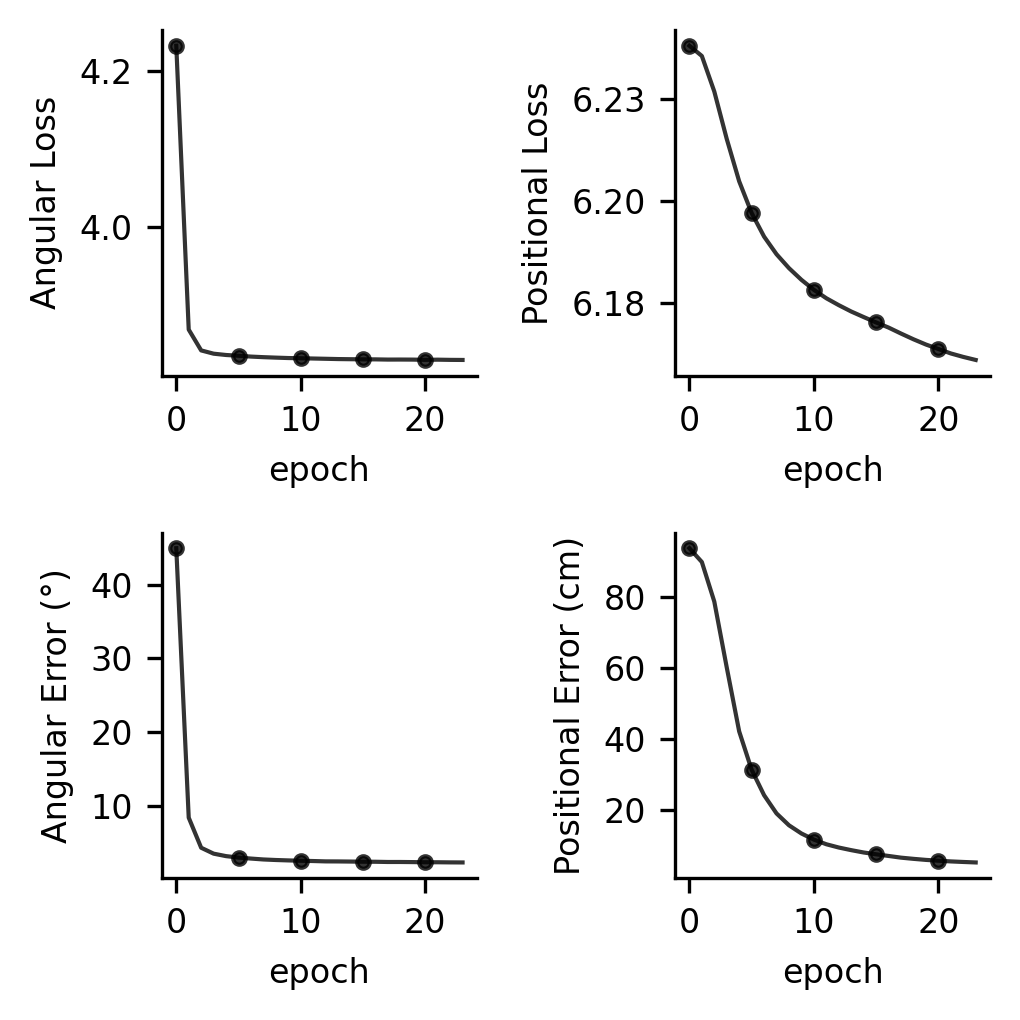

In [3]:
from matplotlib.ticker import FormatStrFormatter


n_steps = options.n_steps

def epoch_mean(x, n_steps):
    x = np.asarray(x)
    n_epochs = len(x) // n_steps
    x = x[:n_epochs * n_steps]
    return x.reshape(n_epochs, n_steps).mean(axis=1)

loss_pas_epoch = epoch_mean(trainer.loss_pas, n_steps)
loss_mec_epoch = epoch_mean(trainer.loss_mec, n_steps)
err_pas_epoch = epoch_mean(trainer.err_pas, n_steps)
err_mec_epoch = epoch_mean(trainer.err_mec, n_steps)

fig, axes = plt.subplots(2, 2, figsize=(3.5, 3.5), dpi=300)

axes[0, 0].plot(loss_pas_epoch, c='black', marker='o', markevery=5, markersize=3, linewidth=1, alpha=0.8)
axes[0, 0].set_ylabel('Angular Loss', fontsize=8)
axes[0, 0].set_xlabel('epoch', fontsize=8)
axes[0, 0].locator_params(axis='y', nbins=2)
axes[0, 0].yaxis.set_major_formatter(FormatStrFormatter('%.1f'))

axes[0, 1].plot(loss_mec_epoch, c='black', marker='o', markevery=5, markersize=3, linewidth=1, alpha=0.8)
axes[0, 1].set_ylabel('Positional Loss', fontsize=8)
axes[0, 1].set_xlabel('epoch', fontsize=8)
axes[0, 1].locator_params(axis='y', nbins=2)
axes[0, 1].yaxis.set_major_formatter(FormatStrFormatter('%.2f'))

axes[1, 0].plot(err_pas_epoch, c='black', marker='o', markevery=5, markersize=3, linewidth=1, alpha=0.8)
axes[1, 0].set_ylabel('Angular Error (°)', fontsize=8)
axes[1, 0].set_xlabel('epoch', fontsize=8)

axes[1, 1].plot(err_mec_epoch, c='black', marker='o', markevery=5, markersize=3, linewidth=1, alpha=0.8)
axes[1, 1].set_ylabel('Positional Error (cm)', fontsize=8)
axes[1, 1].set_xlabel('epoch', fontsize=8)

for ax in axes.flat:
    ax.tick_params(axis='both', labelsize=8)

sns.despine()
fig.tight_layout()
plt.savefig("./docs/training_performance.pdf")
plt.show()




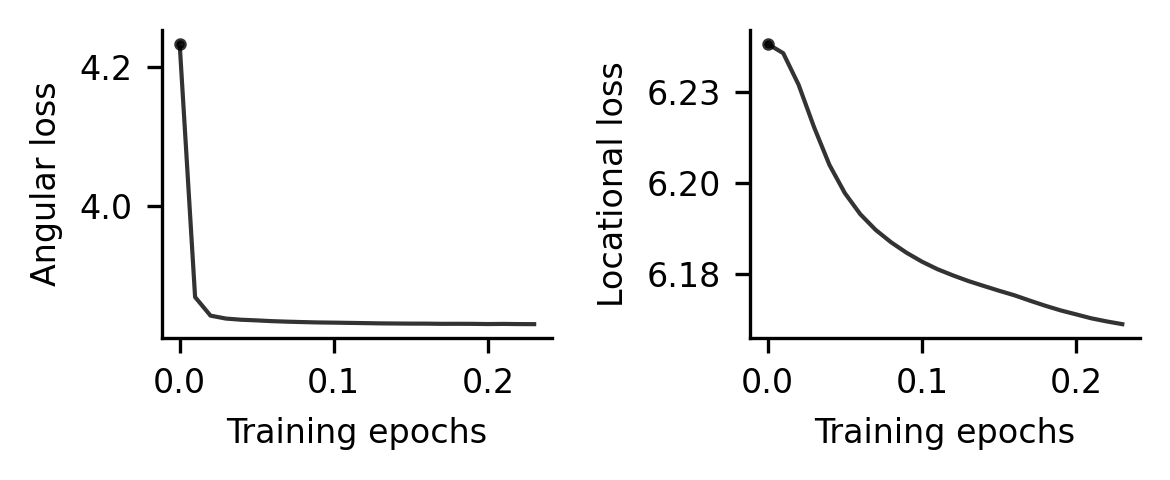

In [4]:
from matplotlib.ticker import FormatStrFormatter

n_steps = options.n_steps

def epoch_mean(x, n_steps):
    x = np.asarray(x)
    n_epochs = len(x) // n_steps
    x = x[:n_epochs * n_steps]
    return x.reshape(n_epochs, n_steps).mean(axis=1)

loss_pas_epoch = epoch_mean(trainer.loss_pas, n_steps)
loss_mec_epoch = epoch_mean(trainer.loss_mec, n_steps)

x_pas = np.arange(len(loss_pas_epoch)) / 100
x_mec = np.arange(len(loss_mec_epoch)) / 100

fig, axes = plt.subplots(1, 2, figsize=(4, 1.7), dpi=300)

axes[0].plot(x_pas, loss_pas_epoch, c='black', marker='o', markevery=100, markersize=2, linewidth=1, alpha=0.8)
axes[0].set_ylabel('Angular loss', fontsize=8)
axes[0].set_xlabel('Training epochs', fontsize=8)
axes[0].locator_params(axis='y', nbins=2)
axes[0].yaxis.set_major_formatter(FormatStrFormatter('%.1f'))

axes[1].plot(x_mec, loss_mec_epoch, c='black', marker='o', markevery=100, markersize=2, linewidth=1, alpha=0.8)
axes[1].set_ylabel('Locational loss', fontsize=8)
axes[1].set_xlabel('Training epochs', fontsize=8)
axes[1].locator_params(axis='y', nbins=2)
axes[1].yaxis.set_major_formatter(FormatStrFormatter('%.2f'))

for ax in axes:
    ax.tick_params(axis='both', labelsize=8)

sns.despine()
fig.tight_layout()
plt.savefig("./docs/training_loss.pdf")
plt.show()


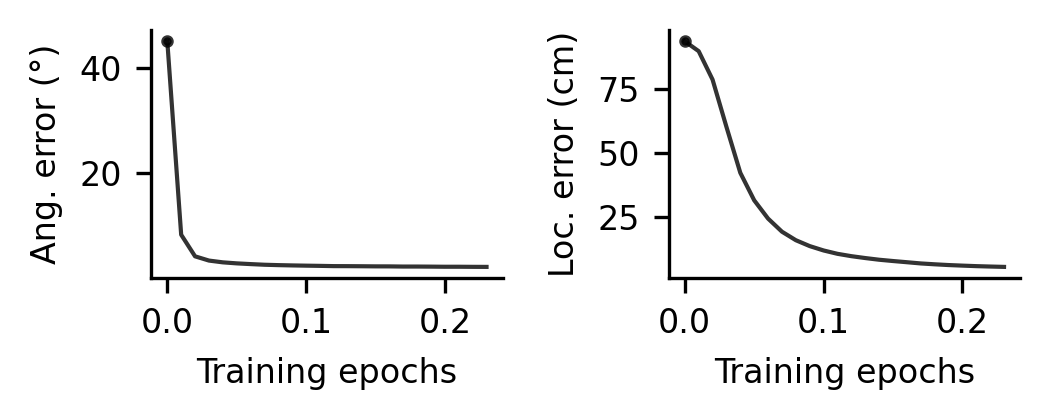

In [5]:
from matplotlib.ticker import FormatStrFormatter

n_steps = options.n_steps

def epoch_mean(x, n_steps):
    x = np.asarray(x)
    n_epochs = len(x) // n_steps
    x = x[:n_epochs * n_steps]
    return x.reshape(n_epochs, n_steps).mean(axis=1)

err_pas_epoch = epoch_mean(trainer.err_pas, n_steps)
err_mec_epoch = epoch_mean(trainer.err_mec, n_steps)

x_pas = np.arange(len(err_pas_epoch)) / 100
x_mec = np.arange(len(err_mec_epoch)) / 100

fig, axes = plt.subplots(1, 2, figsize=(3.6, 1.5), dpi=300)

axes[0].plot(x_pas, err_pas_epoch, c='black', marker='o', markevery=100, markersize=2, linewidth=1, alpha=0.8)
axes[0].set_ylabel('Ang. error (°)', fontsize=8)
axes[0].set_xlabel('Training epochs', fontsize=8)
axes[0].locator_params(axis='y', nbins=2)
axes[0].yaxis.set_major_formatter(FormatStrFormatter('%.0f'))

axes[1].plot(x_mec, err_mec_epoch, c='black', marker='o', markevery=100, markersize=2, linewidth=1, alpha=0.8)
axes[1].set_ylabel('Loc. error (cm)', fontsize=8)
axes[1].set_xlabel('Training epochs', fontsize=8)
axes[1].locator_params(axis='y', nbins=2)
axes[1].yaxis.set_major_formatter(FormatStrFormatter('%.0f'))

for ax in axes:
    ax.tick_params(axis='both', labelsize=8)

sns.despine()
fig.tight_layout()
plt.savefig("./docs/training_error.pdf")
plt.show()


### Evaluate model performance with testing tajectories. NB: training sequence_length is 20, testing is 100. Seems like the network can path-integrate over a muhc larger duration than training duration.

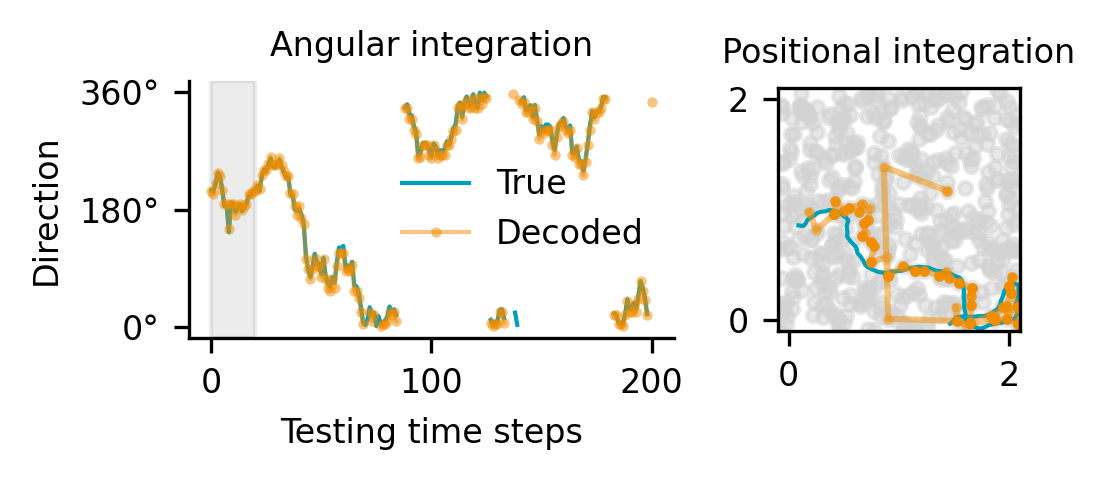

In [6]:
#random seed for reproducibility
np.random.seed(666)

options.sequence_length = 201
options.n_steps = 10
options.batch_size = 20

def break_at_wrap(angle_series, wrap=np.pi):
    a = np.asarray(angle_series).squeeze()
    out = a.copy()
    jumps = np.abs(np.diff(out))
    out[1:][jumps > wrap] = np.nan
    return out

inputs, outputs, targets = trajectory_generator.get_test_batch()
# inputs, outputs, targets = trajectory_generator.get_test_batch_straight(avoid_walls=True)
s, init_actp, ang_v, init_dir_actv = inputs
lmn_inputs = (ang_v, init_dir_actv)
mec_inputs = (s, init_actp)

place_outputs, direction_outputs = outputs
pos, move_dir = targets

move_dir = move_dir.detach().cpu().numpy()
if move_dir.ndim == 3 and move_dir.shape[-1] == 1:
    move_dir = move_dir[..., 0]
pos = pos.detach().cpu().numpy()

# New predict signature
model.eval()
pas_preds, pos_preds = model.predict(lmn_inputs, mec_inputs)

pred_dir_pas = direction_cells.get_nearest_cell_dir(pas_preds, k=3).detach().cpu().numpy()
pred_pos = place_cells.get_nearest_cell_pos(pos_preds, k=1).detach().cpu().numpy()

t = np.arange(move_dir.shape[0])

fig, axs = plt.subplots(1, 2, figsize=(3.6, 1.7), dpi=300, width_ratios=[2, 1])

# left: direction
ax0 = axs[0]
for i in range(1):
    true_line = break_at_wrap(move_dir[:, i])
    pas_line = break_at_wrap(pred_dir_pas[:, i])

    ax0.plot(t, true_line, c='#009FB9', linewidth=1, label='True' if i == 0 else None)
    ax0.plot(t, pas_line, '.-', c='#F18D00', linewidth=1, label='Decoded' if i == 0 else None, alpha=0.5,
             markeredgecolor='none', markeredgewidth=0, markersize=5)

# 前20步阴影
ax0.axvspan(0, 20, color="gray", alpha=0.15, zorder=0)
# ax0.text(10, np.pi * 0.85, "", ha="center", va="center", fontsize=8, color="gray")

ax0.legend(fontsize=8, frameon=False)   
sns.despine(ax=ax0)
ax0.set_yticks([-np.pi, 0, np.pi])
ax0.set_yticklabels(['0°', '180°', '360°'])
ax0.set_xticks([0, len(t)//2, len(t)-1])
ax0.set_xlabel('Testing time steps', fontsize=8)
ax0.set_ylabel('Direction', fontsize=8)
ax0.set_title('Angular integration', fontsize=8)
#ticszie as 8
ax0.tick_params(axis='both', which='major', labelsize=8)

# right: position
ax1 = axs[1]
for i in range(1):
    ax1.plot(pos[:, i, 0], pos[:, i, 1], c='#009FB9', linewidth=1, label='True position' if i == 0 else None)
    ax1.plot(pred_pos[:, i, 0], pred_pos[:, i, 1], '.-', c='#F18D00', label='Decoded position' if i == 0 else None, alpha=0.5,
             markeredgecolor='none', markeredgewidth=0, markersize=5)

us = place_cells.us.detach().cpu().numpy()
ax1.scatter(us[:, 0], us[:, 1], s=10, alpha=0.5, c='lightgrey')
# ax1.legend()
ax1.set_xticks([-1., 1.])
ax1.set_xticklabels(['0', '2'])
ax1.set_yticks([-1., 1.])
ax1.set_yticklabels(['0', '2'])
ax1.set_xlim([-options.box_width/2, options.box_width/2])
ax1.set_ylim([-options.box_height/2, options.box_height/2])
ax1.set_aspect('equal', adjustable='box')
ax1.set_title('Positional integration', fontsize=8)
ax1.tick_params(axis='both', which='major', labelsize=8)

plt.tight_layout()

plt.savefig('./docs/performance.pdf', dpi=300)
